# Unión de las bases geoespaciales por vía — Malla vial, puentes, malla peatonal, semáforos y siniestralidad

Este cuaderno une las capas geoespaciales base tomando la **vía original completa** (sin
subdividir en tramos) como unidad de análisis, y asigna cada elemento de infraestructura y de
siniestralidad a la vía más cercana mediante vecino más próximo (`sjoin_nearest`):

1. La **malla vial** recortada al perímetro POT se conserva con la longitud real de cada vía,
   sin subdividir en tramos de longitud fija.
2. Puentes, semáforos, malla peatonal y **siniestralidad peatonal** se asignan cada uno a la
   vía más cercana.
3. El resultado es una tabla a nivel de vía: una fila = una vía (o una parte de una vía
   multiparte), con sus atributos propios, su dotación de infraestructura y su **conteo de
   siniestros peatonales**, que es la variable objetivo de este cuaderno.

**Insumos requeridos** (generados por los cuadernos previos):

| Archivo | Origen |
|---|---|
| `Data/raw/perimetrourbano (1).gpkg` | POT Decreto 555 |
| `Data/processed/malla_vial_procesada.gpkg` | `EDA_Malla_Vial_Puentes_zona_urbana.ipynb` |
| `Data/processed/puentes_procesado.gpkg` | idem |
| `Data/processed/peatonal_procesada.gpkg` | `EDA_Malla_peatonal_semaforos.ipynb` |
| `Data/processed/semaforos_procesados.gpkg` | idem |
| `Data/processed/siniestros_procesados.gpkg` | `EDA2_Siniestros_Viales_Bogota_peatones...ipynb` (sección 9) |
| `anexo-proyecciones-poblacion-bogota-desagreacion-loc-2018-2035-UPZ-2018-2024.xlsx` | DANE / SDP — proyecciones de población por localidad, 2018-2035 |

Todo en **EPSG:3116** (MAGNA-SIRGAS / Bogotá), condición necesaria para que las distancias
estén en metros reales.


El cuaderno está organizado así:

1. Librerías y parámetros del diseño
2. Carga de insumos y estandarización de CRS
3. Vías como unidad de análisis (sin subdivisión)
4. Agregación de las capas a cada segmento (vecino más cercano)
5. Construcción del dataset final por segmento
6. Vista espacial del resultado
7. Exportación
8. Resumen metodológico

## 1. Librerías y parámetros del diseño

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
plt.rcParams['figure.figsize'] = (9, 6)

# ---------------------------------------------------------------
# PARÁMETROS DEL DISEÑO METODOLÓGICO
# ---------------------------------------------------------------
CRS_PROYECTO = 3116          # MAGNA-SIRGAS / Colombia Bogotá zone (metros)
UMBRAL_RUIDO = 4             # descarta geometrías degeneradas de digitalización
UMBRAL_PEATONAL_M = 15       # distancia máxima para asignar un tramo peatonal a una vía
UMBRAL_SINIESTROS_M = 30     # distancia máxima para asignar un siniestro a una vía

DIR_PROC = 'Data/processed'
os.makedirs(DIR_PROC, exist_ok=True)

print(f"Umbral peatonal: {UMBRAL_PEATONAL_M} m | Umbral siniestros: {UMBRAL_SINIESTROS_M} m")

Umbral peatonal: 15 m | Umbral siniestros: 30 m


## 2. Carga de insumos y estandarización de CRS

Se fuerza el CRS de todas las capas a `EPSG:3116` en vez de asumirlo. Un CRS mal etiquetado
(grados tratados como metros) no falla de forma visible: produce distancias sin sentido físico.

In [2]:
def cargar(ruta, nombre):
    gdf = gpd.read_file(ruta)
    if gdf.crs is None:
        raise ValueError(f"{nombre}: la capa no tiene CRS definido; no se puede asumir.")
    if gdf.crs.to_epsg() != CRS_PROYECTO:
        gdf = gdf.to_crs(epsg=CRS_PROYECTO)
    n0 = len(gdf)
    gdf = gdf[~gdf.geometry.isna() & ~gdf.geometry.is_empty].copy()
    print(f"{nombre:11s}: {n0:>8,} -> {len(gdf):>8,} (descartadas {n0-len(gdf):,} sin geometría)")
    return gdf

perimetro  = cargar("Data/raw/perimetrourbano (1).gpkg", 'perimetro')
malla      = cargar(f"{DIR_PROC}/malla_vial_procesada.gpkg", 'malla')
puentes    = cargar(f"{DIR_PROC}/puentes_procesado.gpkg", 'puentes')
peatonal   = cargar(f"{DIR_PROC}/peatonal_procesada.gpkg", 'peatonal')
semaforos  = cargar(f"{DIR_PROC}/semaforos_procesados.gpkg", 'semaforos')
siniestros = cargar(f"{DIR_PROC}/siniestros_procesados.gpkg", 'siniestros')

# El perímetro se reduce a una sola geometría disuelta: es una máscara, no una tabla.
perimetro = gpd.GeoDataFrame(geometry=[perimetro.union_all()], crs=perimetro.crs)

for nombre, capa in [('perimetro', perimetro), ('malla', malla), ('puentes', puentes),
                     ('peatonal', peatonal), ('semaforos', semaforos), ('siniestros', siniestros)]:
    print(f"{nombre:11s} -> {len(capa):>8,} filas | {capa.crs.to_epsg()} | "
          f"{sorted(capa.geom_type.unique())}")

c:\Users\santiago\Desktop\Universidad\Tesis\Programacion\TT\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column FECHA_ACTO_ADMINISTRATIVO, 2022-07-29T00:00:00.0Z, successfully parsed
  return ogr_read(


perimetro  :        6 ->        6 (descartadas 0 sin geometría)
malla      :  136,957 ->  136,956 (descartadas 1 sin geometría)
puentes    :    1,212 ->    1,212 (descartadas 0 sin geometría)
peatonal   :   46,065 ->   46,065 (descartadas 0 sin geometría)
semaforos  :    1,745 ->    1,745 (descartadas 0 sin geometría)
siniestros :   23,447 ->   21,893 (descartadas 1,554 sin geometría)
perimetro   ->        1 filas | 3116 | ['MultiPolygon']
malla       ->  136,956 filas | 3116 | ['MultiLineString']
puentes     ->    1,212 filas | 3116 | ['MultiPolygon']
peatonal    ->   46,065 filas | 3116 | ['MultiLineString']
semaforos   ->    1,745 filas | 3116 | ['Point']
siniestros  ->   21,893 filas | 3116 | ['Point']


### 2.1 Recorte al perímetro urbano

Mismo criterio para todas las capas: lo que queda fuera del POT no entra al modelo. Se hace
antes de asignar las capas para no gastar cómputo con elementos que después se descartan.

Los semáforos se filtran aparte por coordenadas imposibles (registros corruptos de fuente,
no error de CRS) — ese diagnóstico ya venía del cuaderno anterior.

In [3]:
# Semáforos: exclusión de coordenadas físicamente imposibles (fuera de cualquier
# proyección válida para Bogotá). Se separa del clip porque es un problema de calidad
# de fuente, no de delimitación urbana.
minx, miny, maxx, maxy = perimetro.total_bounds
MARGEN = 5000
corruptos = semaforos[
    (semaforos.geometry.x < minx - MARGEN) | (semaforos.geometry.x > maxx + MARGEN) |
    (semaforos.geometry.y < miny - MARGEN) | (semaforos.geometry.y > maxy + MARGEN)
]
print(f"Semáforos con coordenada corrupta excluidos: {len(corruptos)} de {len(semaforos)}")
semaforos = semaforos.drop(index=corruptos.index).copy()

# Clip al POT de todas las capas
capas = {}
for nombre, capa in [('malla', malla), ('puentes', puentes), ('peatonal', peatonal),
                     ('semaforos', semaforos), ('siniestros', siniestros)]:
    antes = len(capa)
    recortada = gpd.clip(capa, perimetro)
    capas[nombre] = recortada
    print(f"{nombre:11s}: {antes:>8,} -> {len(recortada):>8,} "
          f"({len(recortada)/antes*100:5.1f}% conservado)")
    assert len(recortada) / antes > 0.80, \
        f"{nombre}: el recorte al POT conserva solo {len(recortada)/antes*100:.1f} % — revisar CRS del perímetro"

malla, puentes, peatonal, semaforos, siniestros = (
    capas['malla'], capas['puentes'], capas['peatonal'],
    capas['semaforos'], capas['siniestros'])

Semáforos con coordenada corrupta excluidos: 1 de 1745
malla      :  136,956 ->  131,873 ( 96.3% conservado)
puentes    :    1,212 ->    1,068 ( 88.1% conservado)
peatonal   :   46,065 ->   45,964 ( 99.8% conservado)
semaforos  :    1,744 ->    1,733 ( 99.4% conservado)
siniestros :   21,893 ->   21,716 ( 99.2% conservado)


## 3. Vías como unidad de análisis (sin subdivisión)

Cada vía original se conserva **completa**, con su longitud real, en vez de subdividirse en
tramos de longitud fija: evita introducir cortes artificiales y los tramos de borde que esos
cortes generaban. La longitud de cada vía queda disponible en `long_seg_m`, y es la que hay
que tener en cuenta al comparar conteos entre vías de tamaños muy distintos — una avenida larga
va a acumular más siniestros solo por tener más metros de exposición, no necesariamente porque
sea más peligrosa.

### 3.1 Identificador de la vía madre y filtro de ruido

Se conserva `vial_id` (código original MVI) para poder identificar cada vía, y se descartan
las geometrías por debajo del umbral de ruido: no tiene sentido tratar como vía algo que no
lo es.

In [4]:
id_col = 'MVICODIGO' if 'MVICODIGO' in malla.columns else 'OBJECTID'
malla_base = malla.rename(columns={id_col: 'vial_id'}).copy()

cols_utiles = [c for c in ['vial_id','MVINUMC', 'MVITIPO', 'MVISVIA', 'geometry'] if c in malla_base.columns]
malla_base = malla_base[cols_utiles]

# Explotar multipartes y descartar ruido de digitalización
malla_base = malla_base.explode(index_parts=False).reset_index(drop=True)
malla_base['long_m'] = malla_base.geometry.length

antes = len(malla_base)
malla_base = malla_base[malla_base['long_m'] >= UMBRAL_RUIDO].copy()
print(f"Geometrías descartadas por ruido (< {UMBRAL_RUIDO} m): {antes - len(malla_base)}")
print(f"Vías conservadas: {len(malla_base):,}")
print(f"Longitud total de red: {malla_base['long_m'].sum():,.0f} m")

Geometrías descartadas por ruido (< 4 m): 305
Vías conservadas: 131,704
Longitud total de red: 8,150,387 m


In [5]:
def segmentar_capa(gdf):
    """Cada vía original (tras explotar multipartes) se conserva como un único
    segmento, con su longitud real — ya no se subdivide en tramos de longitud fija.
    Se mantiene el nombre por compatibilidad con el resto del pipeline."""
    base = gdf.explode(index_parts=False).reset_index(drop=True)
    base = base[base.geom_type == 'LineString'].copy()

    seg = base.copy()
    seg['linea_madre_idx'] = seg.index
    seg['long_seg_m'] = seg.geometry.length
    seg = seg.reset_index(drop=True)
    seg['seg_id'] = 'S' + seg.index.astype(str).str.zfill(7)
    return seg

segmentos = segmentar_capa(malla_base)

print(f"Vías (segmentos): {len(segmentos):,}")
print(segmentos['long_seg_m'].describe().round(2))
print(f"\nLongitud total de red: {segmentos['long_seg_m'].sum():,.0f} m")

Vías (segmentos): 131,704
count    131704.00
mean         61.88
std          49.96
min           4.01
25%          31.09
50%          49.59
75%          81.02
max        2893.62
Name: long_seg_m, dtype: float64

Longitud total de red: 8,150,387 m


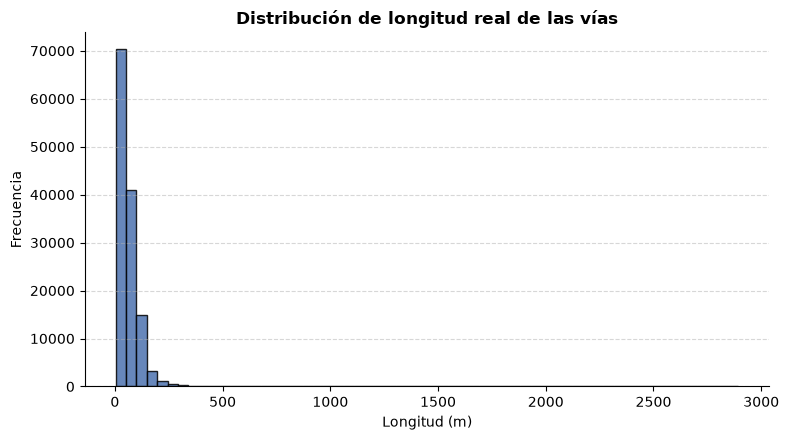

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(segmentos['long_seg_m'], bins=60, color='#4C72B0', edgecolor='black', alpha=0.85)
ax.set_title('Distribución de longitud real de las vías', fontweight='bold')
ax.set_xlabel('Longitud (m)'); ax.set_ylabel('Frecuencia')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

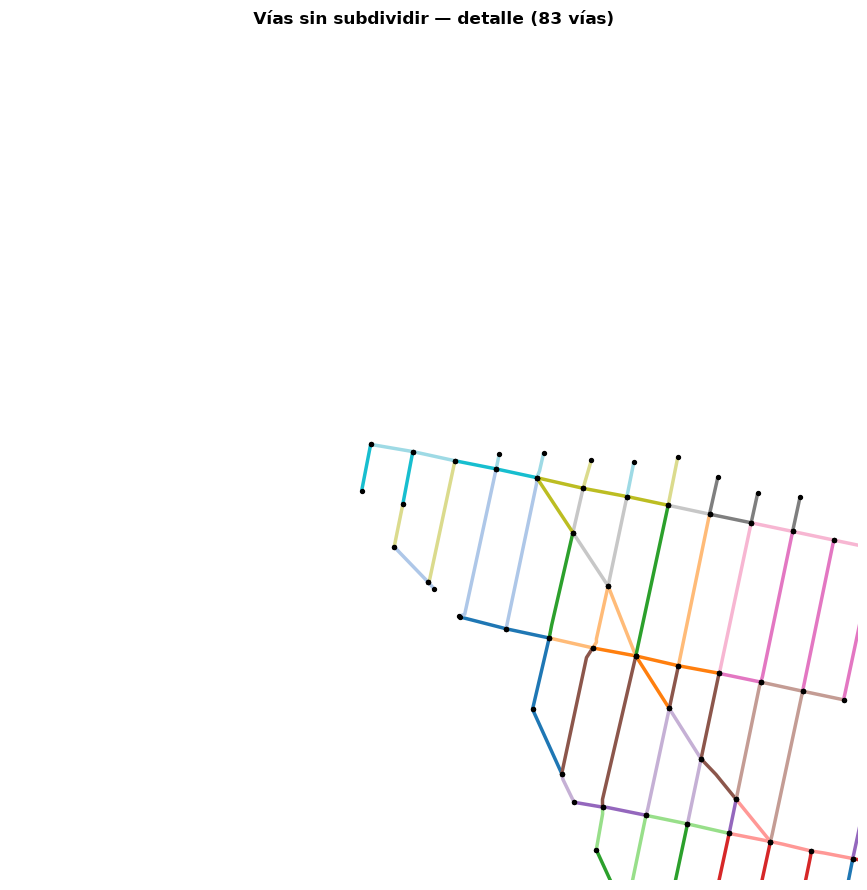

In [7]:
# Inspección visual en una ventana pequeña: cada vía en un color distinto
cx, cy = segmentos.geometry.iloc[len(segmentos)//2].centroid.coords[0]
R = 300

ventana = segmentos.cx[cx-R:cx+R, cy-R:cy+R]
fig, ax = plt.subplots(figsize=(9, 9))
ventana.plot(ax=ax, column='seg_id', cmap='tab20', linewidth=2.5, legend=False)
ventana.geometry.boundary.plot(ax=ax, color='black', markersize=8, zorder=3)
ax.set_xlim(cx-R, cx+R); ax.set_ylim(cy-R, cy+R)
ax.set_title(f'Vías sin subdividir — detalle ({len(ventana)} vías)', fontweight='bold')
ax.set_axis_off(); plt.tight_layout(); plt.show()

## 4. Agregación de las capas a cada segmento (vecino más cercano)

### 4.1 Nota metodológica: asignación por vecino más próximo

Cada elemento de las capas de
infraestructura y de siniestralidad se asigna a la vía más cercana mediante `sjoin_nearest`:

- **Puentes y semáforos** se resumen como **distancia al más cercano**, sin límite de
  distancia — la métrica en sí es la distancia, así que no hace falta descartar nada.
- **Malla peatonal y siniestros** se **agregan** (longitud sumada / conteo) a la vía más
  cercana dentro de un umbral de distancia (`UMBRAL_PEATONAL_M`, `UMBRAL_SINIESTROS_M`), para
  no asignarle a una vía infraestructura o siniestros que en realidad están lejos de ella.




### 4.2 Puentes

Los puentes son polígonos, pero aquí se resumen como la **distancia (m) de la vía al puente
más cercano**, mediante vecino más próximo, sin límite de distancia. Una distancia de 0
significa que la vía cruza o toca físicamente un puente.

In [8]:
# SUPUESTO A VERIFICAR con IDECA/IDU: 1 = Vehicular (catálogo IDECA), 2 = Peatonal (por confirmar)
TIPO_VEHICULAR = 1
TIPO_PEATONAL  = 2   # si la verificación indica otro código, cambiar SOLO aquí

COL_ID_PUENTE = 'PueCodigo' if 'PueCodigo' in puentes.columns else puentes.columns[0]

def _dist_min_a(capa, nombre_col):
    """Distancia (m) de cada segmento al elemento más cercano de `capa`, sin límite de distancia."""
    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        capa[[COL_ID_PUENTE, 'geometry']],
        distance_col=nombre_col
    )
    # groupby.min resuelve los empates que sjoin_nearest devuelve como filas duplicadas
    return cercano.groupby('seg_id', as_index=False)[nombre_col].min()

def agregar_puentes():
    """Distancias (m) de cada vía al puente más cercano: peatonal, vehicular y de cualquier tipo."""
    puentes_peat = puentes[puentes['PueTipo'] == TIPO_PEATONAL]
    puentes_veh  = puentes[puentes['PueTipo'] == TIPO_VEHICULAR]

    res = _dist_min_a(puentes, 'dist_puente_m')
    if len(puentes_peat):
        res = res.merge(_dist_min_a(puentes_peat, 'dist_puente_peatonal_m'), on='seg_id', how='left')
    if len(puentes_veh):
        res = res.merge(_dist_min_a(puentes_veh, 'dist_puente_vehicular_m'), on='seg_id', how='left')
    return res

puentes_agg = agregar_puentes()

for col, etiqueta in [('dist_puente_m', 'cualquier puente'),
                      ('dist_puente_peatonal_m', 'puente peatonal (supuesto tipo 2)'),
                      ('dist_puente_vehicular_m', 'puente vehicular (tipo 1)')]:
    if col in puentes_agg:
        s = puentes_agg[col]
        print(f"Distancia a {etiqueta} -> media {s.mean():.1f} m | mediana {s.median():.1f} m | "
              f"vías sobre un puente (dist=0): {(s == 0).sum():,} | "
              f"vías con dato: {s.notna().sum():,} de {len(segmentos):,}")

Distancia a cualquier puente -> media 463.5 m | mediana 379.4 m | vías sobre un puente (dist=0): 3,261 | vías con dato: 131,704 de 131,704
Distancia a puente peatonal (supuesto tipo 2) -> media 573.5 m | mediana 481.8 m | vías sobre un puente (dist=0): 1,148 | vías con dato: 131,704 de 131,704
Distancia a puente vehicular (tipo 1) -> media 594.3 m | mediana 504.5 m | vías sobre un puente (dist=0): 2,361 | vías con dato: 131,704 de 131,704


### 4.3 Semáforos

Puntos: se resumen como la **distancia (m) al semáforo más cercano**, mediante vecino más
próximo, sin límite de distancia.

In [9]:
COL_ID_SEM = 'OBJECTID' if 'OBJECTID' in semaforos.columns else semaforos.columns[0]

def agregar_semaforos():
    """Distancia (m) de cada vía al semáforo más cercano, sin límite de distancia."""
    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        semaforos[[COL_ID_SEM, 'geometry']],
        distance_col='dist_semaforo_m'
    )
    return (cercano.groupby('seg_id', as_index=False)['dist_semaforo_m'].min())

semaforos_agg = agregar_semaforos()
print(f"Distancia al semáforo más cercano -> media {semaforos_agg['dist_semaforo_m'].mean():.1f} m | "
      f"mediana {semaforos_agg['dist_semaforo_m'].median():.1f} m | "
      f"máxima {semaforos_agg['dist_semaforo_m'].max():.1f} m | "
      f"vías con dato: {semaforos_agg['dist_semaforo_m'].notna().sum():,} de {len(segmentos):,}")

Distancia al semáforo más cercano -> media 401.7 m | mediana 238.8 m | máxima 4976.2 m | vías con dato: 131,704 de 131,704


### 4.4 Malla peatonal

Es una capa de **líneas**, así que un conteo de elementos dice poco (depende de cómo esté
fragmentada la fuente). Cada tramo de malla peatonal se asigna a la vía más cercana (hasta
`UMBRAL_PEATONAL_M`) mediante vecino más próximo, y se suma la longitud de los tramos
asignados: la variable informativa es la **longitud de infraestructura peatonal asignada a la
vía**, y su versión normalizada por longitud de vía (metros de andén por metro de vía), que es
comparable entre vías de distinta longitud.

In [10]:
def agregar_peatonal(umbral_m=UMBRAL_PEATONAL_M):
    """Para cada vía, tramo peatonal más cercano (invertido respecto a antes: se
    consulta desde la vía, no desde el tramo peatonal, para que vías vecinas no
    compitan por un mismo tramo peatonal)."""
    peatonal_ = peatonal.copy()
    peatonal_['long_peat_elem'] = peatonal_.geometry.length

    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        peatonal_[['long_peat_elem', 'geometry']],
        max_distance=umbral_m, distance_col='dist_peatonal_m'
    )
    # Si una vía tiene dos tramos peatonales exactamente a la misma distancia mínima,
    # sjoin_nearest puede duplicar la fila; nos quedamos con uno solo por vía.
    cercano = cercano.drop_duplicates(subset='seg_id', keep='first')

    return cercano[['seg_id', 'dist_peatonal_m', 'long_peat_elem']].rename(
        columns={'long_peat_elem': 'long_peatonal_cercano_m'})

peatonal_agg = agregar_peatonal()
print(f"Vías con infraestructura peatonal asignada (<= {UMBRAL_PEATONAL_M} m): "
      f"{len(peatonal_agg):,} ({len(peatonal_agg)/len(segmentos)*100:.2f}%) | "
      f"distancia media: {peatonal_agg['dist_peatonal_m'].mean():.2f} m")

Vías con infraestructura peatonal asignada (<= 15 m): 74,417 (56.50%) | distancia media: 0.23 m


### 4.5 Conteo de siniestros por segmento (variable objetivo)

El **conteo de siniestros peatonales por vía** es la variable objetivo de este cuaderno. Cada
siniestro se asigna a la vía más cercana (hasta `UMBRAL_SINIESTROS_M`) mediante vecino más
próximo, así que cada siniestro pertenece a una única vía — no hay doble conteo que resolver.
Se agrega con más detalle que las covariables: conteo total de siniestros, número de peatones
afectados, y descriptores de contexto adicionales (desagregación por `ESTADO`, porcentaje
nocturno y momento del siniestro) que quedan disponibles como variables descriptivas, no como
la definición del objetivo.

In [11]:
print("Columnas disponibles en siniestros:")
print(sorted(siniestros.columns.tolist()))
print()
if 'ESTADO' in siniestros.columns:
    print(siniestros['ESTADO'].value_counts(dropna=False))

Columnas disponibles en siniestros:
['ANO_OCURRENCIA_ACC', 'CAUSA_PRINCIPAL', 'CLASE', 'CODIGO_ACCIDENTADO', 'CODIGO_ACCIDENTE', 'CODIGO_LOCALIDAD', 'CONDICION', 'DIA_SEMANA', 'DIRECCION', 'DISENO_LUGAR', 'DISENO_LUGAR_DESC', 'EDAD', 'ESTADO', 'FECHA', 'FECHA_HORA_ACC', 'FECHA_OCURRENCIA_ACC', 'HORA', 'HORA_DIA', 'LATITUD', 'LOCALIDAD_DESC', 'LONGITUD', 'MES', 'SEXO', 'VEHICULO', 'geometry']

ESTADO
HERIDO    20327
MUERTO     1387
ILESO         2
Name: count, dtype: int64


In [12]:
def agregar_siniestros(umbral_m=UMBRAL_SINIESTROS_M):
    base_sin = siniestros.reset_index(drop=True).copy()
    base_sin['_elem_id'] = base_sin.index

    pares = gpd.sjoin_nearest(
        base_sin, segmentos[['seg_id', 'geometry']],
        max_distance=umbral_m, distance_col='dist_m'
    )
    # Empates a la misma distancia mínima: nos quedamos con uno solo por siniestro
    pares = pares.drop_duplicates(subset='_elem_id', keep='first')

    sin_asignar = len(base_sin) - pares['_elem_id'].nunique()
    print(f"Siniestros sin vía asignada a {umbral_m} m: {sin_asignar}")

    col_acc = 'CODIGO_ACCIDENTE' if 'CODIGO_ACCIDENTE' in pares.columns else '_elem_id'

    agg = {'n_peatones_afectados': ('_elem_id', 'nunique'),
           'n_siniestros': (col_acc, 'nunique')}
    if 'HORA_DIA' in pares.columns:
        agg['pct_nocturno'] = ('HORA_DIA', lambda s: ((s >= 19) | (s <= 5)).mean() * 100)
    if 'poblacion_total' in pares.columns:
        agg['poblacion_localidad_media'] = ('poblacion_total', 'mean')

    base = pares.groupby('seg_id').agg(**agg).reset_index()

    # Desagregación por gravedad: una columna por estado del peatón (se excluye 'ileso',
    # no aporta como variable de este dataset)
    if 'ESTADO' in pares.columns:
        piv = (pd.crosstab(pares['seg_id'], pares['ESTADO'])
                 .add_prefix('n_').rename(columns=str.lower).reset_index())
        if 'n_ileso' in piv.columns:
            piv = piv.drop(columns='n_ileso')
        base = base.merge(piv, on='seg_id', how='left')

    # Año más reciente y rango temporal cubierto en la vía
    if 'ANO_OCURRENCIA_ACC' in pares.columns:
        años = (pares.groupby('seg_id')['ANO_OCURRENCIA_ACC']
                     .agg(ano_min='min', ano_max='max').reset_index())
        base = base.merge(años, on='seg_id', how='left')

    return base

siniestros_agg = agregar_siniestros()

print(f"\nVías con siniestro: {len(siniestros_agg):,} ({len(siniestros_agg)/len(segmentos)*100:.2f}%) | "
      f"total asignaciones: {siniestros_agg['n_peatones_afectados'].sum():,} "
      f"(peatones afectados reales: {len(siniestros):,})")

Siniestros sin vía asignada a 30 m: 15

Vías con siniestro: 13,323 (10.12%) | total asignaciones: 21,701 (peatones afectados reales: 21,716)


### 4.6 Cobertura: ¿qué siniestros no captura el umbral de distancia?

Un siniestro que no cae dentro de `UMBRAL_SINIESTROS_M` de ninguna vía queda **fuera del
modelo**: o su geocodificación es imprecisa, o ocurrió en una vía que no está en la Malla Vial
Integral. Si esta fracción es alta, es el argumento empírico para subir el umbral.

In [13]:
pct_cobertura = siniestros_agg['n_peatones_afectados'].sum() / len(siniestros) * 100
print(f"Cobertura con umbral de {UMBRAL_SINIESTROS_M} m: {pct_cobertura:.2f}% de los "
      f"siniestros peatonales quedaron asignados a alguna vía.")

Cobertura con umbral de 30 m: 99.93% de los siniestros peatonales quedaron asignados a alguna vía.


### 4.7 Integración del anexo de proyecciones de población

Se cruza cada siniestro con la **población proyectada de su localidad en el año en que ocurrió**
(anexo `anexo-proyecciones-poblacion-bogota-...-2018-2035-UPZ-2018-2024.xlsx`, hoja `Localidades`).
Esto permite, más adelante, leer la siniestralidad no solo en conteos absolutos sino **normalizada
por población expuesta** (tasa por 100.000 habitantes), que es la métrica estándar en epidemiología
de siniestros viales — dos localidades con el mismo número de siniestros no tienen el mismo riesgo
si una tiene el triple de habitantes.

La hoja `Localidades` trae, para cada localidad y año, el desglose `Cabecera Municipal` /
`Centros Poblados y Rural Disperso` / `Total`. Se usa la fila `AREA == 'Total'`, que es la
población total de la localidad ese año.

In [14]:
RUTA_ANEXO_POBLACION = "data/raw/anexo-proyecciones-poblacion-bogota-desagreacion-loc-2018-2035-UPZ-2018-2024.xlsx"

# La hoja trae 11 filas de título/metadatos antes del encabezado real de columnas
poblacion_raw = pd.read_excel(RUTA_ANEXO_POBLACION, sheet_name='Localidades', header=11)
poblacion_raw = poblacion_raw[poblacion_raw['NOM_LOC'].notna() & (poblacion_raw['NOM_LOC'] != 'NOM_LOC')].copy()

poblacion_localidad = (
    poblacion_raw[poblacion_raw['AREA'] == 'Total']
    [['COD_LOC', 'NOM_LOC', 'AÑO', 'TOTAL HOMBRES', 'TOTAL MUJERES', 'TOTAL']]
    .rename(columns={'AÑO': 'anio', 'TOTAL': 'poblacion_total',
                      'TOTAL HOMBRES': 'poblacion_hombres', 'TOTAL MUJERES': 'poblacion_mujeres'})
    .reset_index(drop=True)
)
poblacion_localidad['anio'] = poblacion_localidad['anio'].astype(int)

print(f"Anexo cargado: {len(poblacion_localidad):,} filas | "
      f"{poblacion_localidad['NOM_LOC'].nunique()} localidades | "
      f"años {poblacion_localidad['anio'].min()}–{poblacion_localidad['anio'].max()}")
poblacion_localidad.head()

Anexo cargado: 360 filas | 20 localidades | años 2018–2035


,COD_LOC,NOM_LOC,anio,poblacion_hombres,poblacion_mujeres,poblacion_total
0,1,Usaquén,2018,246937,288756,535693
1,2,Chapinero,2018,74402,82077,156479
2,3,Santa Fe,2018,51631,52354,103985
3,4,San Cristóbal,2018,186898,198616,385514
4,5,Usme,2018,176971,186423,363394


**Normalización de nombres de localidad.** Los nombres de localidad en el anexo (con tildes,
capitalización estándar) casi nunca coinciden carácter a carácter con los de la fuente de
siniestros (típicamente en mayúsculas y sin tildes). Se normalizan ambos lados antes de cruzar.

In [15]:
import unicodedata

def normalizar_texto(s):
    """Mayúsculas, sin tildes, sin espacios sobrantes — para cruces de texto robustos."""
    if pd.isna(s):
        return s
    s = str(s).strip().upper()
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return s

poblacion_localidad['loc_norm'] = poblacion_localidad['NOM_LOC'].map(normalizar_texto)

**Detección de las columnas de localidad y año en `siniestros`.** Se prueba una lista de nombres
candidatos en vez de asumir uno fijo, siguiendo el mismo criterio defensivo usado en el resto del
cuaderno (p. ej. `MVICODIGO`/`OBJECTID`). El año ya se usa en la sección 4.5 como `ANO_OCURRENCIA_ACC`;
aquí se reutiliza la misma columna para mantener consistencia.

In [16]:
CANDIDATOS_LOCALIDAD = ['LOCALIDAD', 'LOCALIDAD_ACC', 'LOCALIDAD_HECHO', 'LOCALIDAD_SIN',
                        'NOMBRE_LOCALIDAD', 'NOM_LOCALIDAD', 'LOC_NOMBRE', 'LOCALIDAD_DESC']
COL_LOCALIDAD_SIN = next((c for c in CANDIDATOS_LOCALIDAD if c in siniestros.columns), None)
COL_ANIO_SIN = 'ANO_OCURRENCIA_ACC' if 'ANO_OCURRENCIA_ACC' in siniestros.columns else None

print("Columna de localidad detectada en siniestros:", COL_LOCALIDAD_SIN)
print("Columna de año detectada en siniestros       :", COL_ANIO_SIN)

if COL_LOCALIDAD_SIN is None or COL_ANIO_SIN is None:
    print("\n  No se detectó automáticamente alguna de las dos columnas necesarias.")
    print("Columnas disponibles en siniestros:", sorted(siniestros.columns.tolist()))
    print("Ajusta CANDIDATOS_LOCALIDAD (o COL_ANIO_SIN) con el nombre real de la columna y vuelve a",
          "correr esta celda antes de continuar con el resto de la sección 4.7.")

Columna de localidad detectada en siniestros: LOCALIDAD_DESC
Columna de año detectada en siniestros       : ANO_OCURRENCIA_ACC


**Cruce siniestro → población de su localidad-año.** Los años del anexo van de 2018 a 2035; un
siniestro con año fuera de ese rango (p. ej. anterior a 2018) se empareja con el límite más cercano
en vez de perderse, y queda documentado como tal.

In [17]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    siniestros['_loc_norm'] = siniestros[COL_LOCALIDAD_SIN].map(normalizar_texto)
    siniestros['_anio_sin'] = pd.to_numeric(siniestros[COL_ANIO_SIN], errors='coerce').astype('Int64')

    anio_min, anio_max = poblacion_localidad['anio'].min(), poblacion_localidad['anio'].max()
    fuera_de_rango = ((siniestros['_anio_sin'] < anio_min) | (siniestros['_anio_sin'] > anio_max)).sum()
    if fuera_de_rango:
        print(f"{fuera_de_rango} siniestros con año fuera de {anio_min}-{anio_max}; "
              f"se emparejan con el límite más cercano del anexo.")
    siniestros['_anio_match'] = siniestros['_anio_sin'].clip(lower=anio_min, upper=anio_max)

    siniestros = siniestros.merge(
        poblacion_localidad[['loc_norm', 'anio', 'poblacion_total', 'poblacion_hombres', 'poblacion_mujeres']],
        left_on=['_loc_norm', '_anio_match'], right_on=['loc_norm', 'anio'], how='left'
    ).drop(columns=['loc_norm', 'anio'])

    pct_match = siniestros['poblacion_total'].notna().mean() * 100
    print(f"\nSiniestros con población de localidad-año emparejada: {pct_match:.1f}% "
          f"({siniestros['poblacion_total'].notna().sum():,} de {len(siniestros):,})")

    sin_match = sorted(siniestros.loc[siniestros['poblacion_total'].isna(), '_loc_norm'].dropna().unique())
    if sin_match:
        print("\nValores de localidad SIN coincidencia en el anexo (revisar ortografía/alcance):")
        print(sin_match)

11929 siniestros con año fuera de 2018-2035; se emparejan con el límite más cercano del anexo.

Siniestros con población de localidad-año emparejada: 100.0% (21,716 de 21,716)


**Tasa de siniestralidad por 100.000 habitantes, por localidad y año.** Este es el indicador
normalizado que responde "¿dónde es más riesgoso caminar?", independiente del tamaño poblacional
de cada localidad — a diferencia del conteo crudo, que simplemente favorece a las localidades más
grandes.

In [18]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio = (
        siniestros.dropna(subset=['poblacion_total'])
                  .groupby(['_loc_norm', '_anio_match'])
                  .agg(n_siniestros=('_anio_sin', 'size'),
                       poblacion_total=('poblacion_total', 'first'))
                  .reset_index()
                  .rename(columns={'_loc_norm': 'localidad', '_anio_match': 'anio'})
    )
    resumen_localidad_anio['siniestros_por_100k_hab'] = (
        resumen_localidad_anio['n_siniestros'] / resumen_localidad_anio['poblacion_total'] * 100_000
    ).round(2)
    resumen_localidad_anio = resumen_localidad_anio.sort_values(['localidad', 'anio']).reset_index(drop=True)

    print(resumen_localidad_anio.shape)
    resumen_localidad_anio.head(15)

(57, 5)


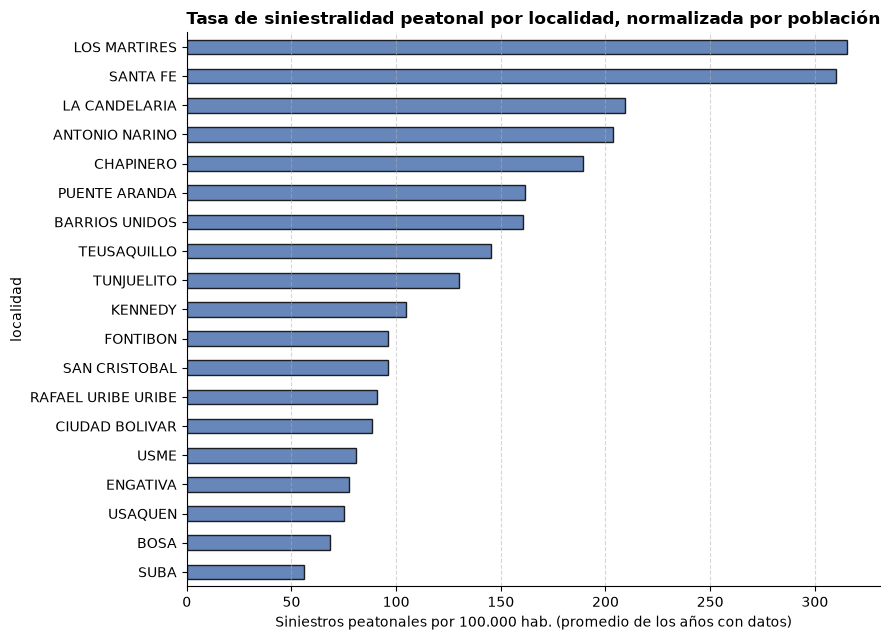

In [19]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    tasa_media_localidad = (resumen_localidad_anio.groupby('localidad')['siniestros_por_100k_hab']
                            .mean().sort_values(ascending=False))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    tasa_media_localidad.plot(kind='barh', ax=ax, color='#4C72B0', edgecolor='black', alpha=0.85)
    ax.invert_yaxis()
    ax.set_xlabel('Siniestros peatonales por 100.000 hab. (promedio de los años con datos)')
    ax.set_title('Tasa de siniestralidad peatonal por localidad, normalizada por población',
                 fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout(); plt.show()

**Propagación al nivel de vía.** `agregar_siniestros` ya incluye la lógica para incorporar la
población promedio de la(s) localidad(es)-año representada(s) por los siniestros de cada vía
(`poblacion_localidad_media`) cuando la columna `poblacion_total` está disponible en
`siniestros`. Basta con volver a llamarla ahora que ese cruce ya se hizo arriba — se recalcula
`siniestros_agg`, que es el que la sección 5 usa para construir el dataset final.

In [20]:
siniestros_agg = agregar_siniestros()

if 'poblacion_localidad_media' in siniestros_agg.columns:
    print(f"Vías con población de localidad asociada: "
          f"{siniestros_agg['poblacion_localidad_media'].notna().sum():,}")

Siniestros sin vía asignada a 30 m: 15
Vías con población de localidad asociada: 13,323


## 5. Construcción del dataset final por segmento

Una fila = una vía. Las covariables de infraestructura y la variable respuesta —el **conteo
de siniestros por segmento**— vienen todas de una asignación por vecino más próximo, así que
no hace falta distinguir modos de agregación.

In [21]:
def construir_dataset():
    ds = segmentos[['seg_id', 'vial_id', 'long_seg_m', 'geometry'] +
                   [c for c in ['MVITIPO', 'MVISVIA'] if c in segmentos.columns]].copy()

    ds = ds.merge(puentes_agg,    on='seg_id', how='left')
    ds = ds.merge(semaforos_agg,  on='seg_id', how='left')
    ds = ds.merge(peatonal_agg,   on='seg_id', how='left')
    ds = ds.merge(siniestros_agg, on='seg_id', how='left')

    # Conteos ausentes = ausencia real del fenómeno, no dato faltante
    cols_conteo = [c for c in ds.columns if c.startswith('n_')]
    ds[cols_conteo] = ds[cols_conteo].fillna(0)
    for c in cols_conteo:
        if ds[c].dropna().mod(1).eq(0).all():
            ds[c] = ds[c].astype(int)

    # Infraestructura peatonal: NaN en dist_peatonal_m = ninguna a <= UMBRAL_PEATONAL_M
    ds['tiene_infra_peatonal'] = ds['dist_peatonal_m'].notna()

    if 'n_peatones_afectados' in ds.columns:
        ds['tuvo_siniestro'] = ds['n_peatones_afectados'] > 0
    return ds

dataset_final = construir_dataset()

print(f"Dataset final: {dataset_final.shape}")
print(f"% con infraestructura peatonal asignada : {dataset_final['tiene_infra_peatonal'].mean()*100:.2f}%")
print(f"% con siniestro                         : {dataset_final['tuvo_siniestro'].mean()*100:.2f}%")
print(f"Siniestros totales capturados            : {dataset_final['n_peatones_afectados'].sum():,}")
dataset_final.head()

Dataset final: (131704, 22)
% con infraestructura peatonal asignada : 56.50%
% con siniestro                         : 10.12%
Siniestros totales capturados            : 21,701


,seg_id,vial_id,long_seg_m,geometry,MVITIPO,MVISVIA,dist_puente_m,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,dist_peatonal_m,long_peatonal_cercano_m,n_peatones_afectados,n_siniestros,pct_nocturno,poblacion_localidad_media,n_herido,n_muerto,ano_min,ano_max,tiene_infra_peatonal,tuvo_siniestro
0,S0000000,91428,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",CL,SD,2149.708556,2149.708556,2248.410504,1410.063301,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN,False,False
1,S0000001,103844,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",CL,SD,2130.397897,2130.397897,2218.697332,1378.963885,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN,False,False
2,S0000002,136273,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",DG,SD,2108.777826,2108.777826,2173.881717,1232.553221,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN,False,False
3,S0000003,122955,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",KR,SD,2102.083822,2102.083822,2208.676848,1410.063301,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN,False,False
4,S0000004,106448,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",DG,SD,2106.174016,2106.174016,2164.688445,1255.390362,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN,False,False


### 5.1 Desbalance de la variable respuesta (conteo de siniestros por segmento)

La mayoría de las vías de Bogotá no tuvo ningún siniestro peatonal. Cuantificarlo aquí
justifica las decisiones de modelado (pesos de clase, métricas distintas de exactitud) y
anticipa si conviene un modelo de conteos inflado en ceros.

Vías sin siniestros : 118,381 (89.88%)
Vías con >=1         : 13,323 (10.12%)
Máximo en una vía    : 54

Distribución de conteos:
n_peatones_afectados
0     118381
1       9116
2       2360
3        937
4        402
5        212
6        114
7         69
8         29
9         21
10        19
11        12
Name: count, dtype: int64


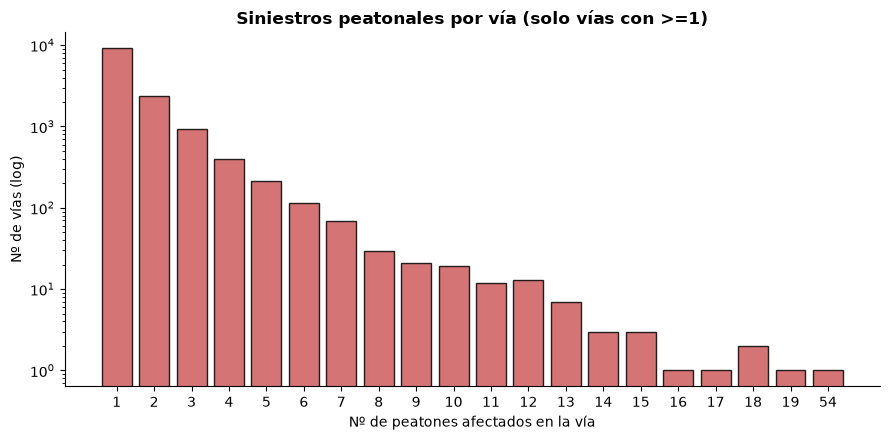

In [22]:
vr = dataset_final['n_peatones_afectados']
print(f"Vías sin siniestros : {(vr == 0).sum():,} ({(vr == 0).mean()*100:.2f}%)")
print(f"Vías con >=1         : {(vr > 0).sum():,} ({(vr > 0).mean()*100:.2f}%)")
print(f"Máximo en una vía    : {vr.max()}")
print(f"\nDistribución de conteos:")
print(vr.value_counts().sort_index().head(12))

fig, ax = plt.subplots(figsize=(9, 4.5))
conteo_vr = vr[vr > 0].value_counts().sort_index()
ax.bar(conteo_vr.index.astype(str), conteo_vr.values,
       color='indianred', edgecolor='black', alpha=0.85)
ax.set_yscale('log')
ax.set_title('Siniestros peatonales por vía (solo vías con >=1)', fontweight='bold')
ax.set_xlabel('Nº de peatones afectados en la vía'); ax.set_ylabel('Nº de vías (log)')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Vista espacial del resultado

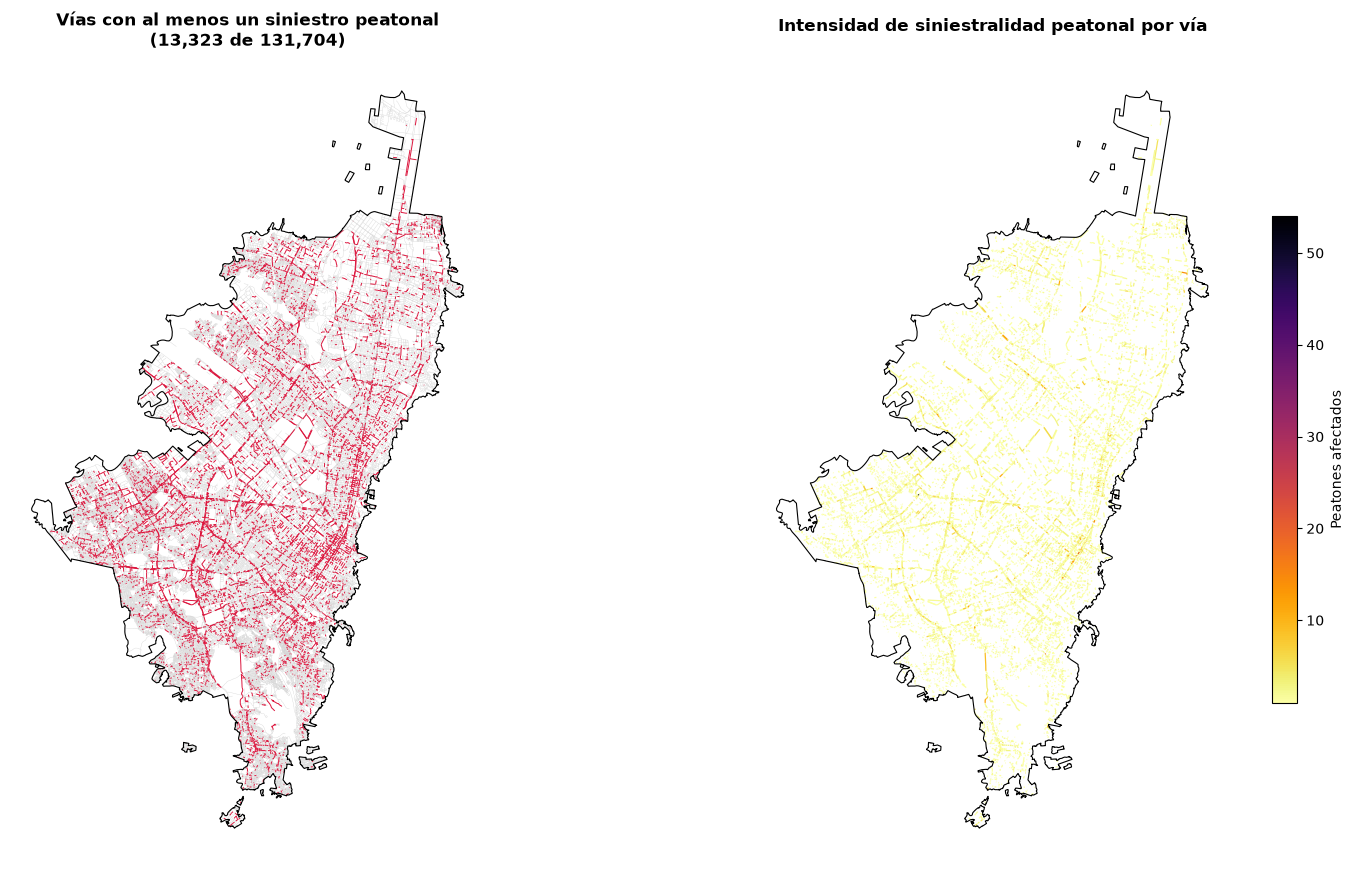

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# Izquierda: red coloreada por presencia de siniestros
sin_sin = dataset_final[~dataset_final['tuvo_siniestro']]
con_sin = dataset_final[dataset_final['tuvo_siniestro']]
sin_sin.plot(ax=axes[0], color='lightgray', linewidth=0.25, zorder=1)
con_sin.plot(ax=axes[0], color='crimson', linewidth=0.7, zorder=2)
perimetro.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
axes[0].set_title(f'Vías con al menos un siniestro peatonal\n'
                  f'({len(con_sin):,} de {len(dataset_final):,})', fontweight='bold')

# Derecha: intensidad
con_sin.plot(ax=axes[1], column='n_peatones_afectados', cmap='inferno_r',
             linewidth=0.9, legend=True, scheme=None,
             legend_kwds={'label': 'Peatones afectados', 'shrink': 0.6})
perimetro.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
axes[1].set_title('Intensidad de siniestralidad peatonal por vía', fontweight='bold')

for ax in axes:
    ax.set_axis_off()
plt.tight_layout(); plt.show()

## 7. Exportación

Se exporta el dataset a nivel de vía.

In [ ]:
dataset_final

,seg_id,vial_id,long_seg_m,geometry,MVITIPO,MVISVIA,dist_puente_m,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,dist_peatonal_m,long_peatonal_cercano_m,n_peatones_afectados,n_siniestros,pct_nocturno,poblacion_localidad_media,n_herido,n_muerto,ano_min,ano_max,tiene_infra_peatonal,tuvo_siniestro
0,S0000000,91428,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",CL,SD,2149.708556,2149.708556,2248.410504,1410.063301,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
1,S0000001,103844,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",CL,SD,2130.397897,2130.397897,2218.697332,1378.963885,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
2,S0000002,136273,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",DG,SD,2108.777826,2108.777826,2173.881717,1232.553221,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
3,S0000003,122955,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",KR,SD,2102.083822,2102.083822,2208.676848,1410.063301,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
4,S0000004,106448,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",DG,SD,2106.174016,2106.174016,2164.688445,1255.390362,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False


In [24]:
salida = f'{DIR_PROC}/segmentos_unificado.gpkg'

# Capa principal de análisis
dataset_final.to_file(salida, layer='segmentos', driver='GPKG')

# Versión tabular para modelado (sin geometría)
cols_drop = ['seg_id', 'vial_id', 'geometry', 'MVITIPO', 'MVISVIA',
       'dist_puente_m', 'long_peatonal_cercano_m',
       'n_peatones_afectados', 'pct_nocturno', 'ano_min',
       'ano_max', 'tiene_infra_peatonal', 'tuvo_siniestro']
dataset_final = dataset_final.fillna(0)
dataset_final.drop(columns=cols_drop).to_csv(
    f'{DIR_PROC}/segmentos_unificado.csv', index=False)

# Tabla de siniestralidad normalizada por población (anexo de proyecciones), por localidad y año
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio.to_csv(f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv', index=False)

print('GeoPackage:', salida, '| capa: segmentos')
print('CSV       :', f'{DIR_PROC}/segmentos_unificado.csv')
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    print('CSV       :', f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv')
print(f'\nDataset final: {dataset_final.shape[0]:,} vías x {dataset_final.shape[1]} columnas')

GeoPackage: Data/processed/segmentos_unificado.gpkg | capa: segmentos
CSV       : Data/processed/segmentos_unificado.csv
CSV       : Data/processed/siniestros_tasa_100k_localidad_anio.csv

Dataset final: 131,704 vías x 22 columnas


In [25]:
dataset_final

,seg_id,vial_id,long_seg_m,geometry,MVITIPO,MVISVIA,dist_puente_m,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,dist_peatonal_m,long_peatonal_cercano_m,n_peatones_afectados,n_siniestros,pct_nocturno,poblacion_localidad_media,n_herido,n_muerto,ano_min,ano_max,tiene_infra_peatonal,tuvo_siniestro
0,S0000000,91428,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",CL,SD,2149.708556,2149.708556,2248.410504,1410.063301,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
1,S0000001,103844,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",CL,SD,2130.397897,2130.397897,2218.697332,1378.963885,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
2,S0000002,136273,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",DG,SD,2108.777826,2108.777826,2173.881717,1232.553221,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
3,S0000003,122955,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",KR,SD,2102.083822,2102.083822,2208.676848,1410.063301,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
4,S0000004,106448,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",DG,SD,2106.174016,2106.174016,2164.688445,1255.390362,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131699,S0131699,94449,138.327740,"LINESTRING (1002997.328 1025346.31, 1002881.52...",,SD,2074.655202,3199.597149,2074.655202,4829.450372,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
131700,S0131700,98523,47.720755,"LINESTRING (1002881.529 1025421.974, 1002841.7...",,SD,2202.181128,3310.416595,2202.181128,4938.129880,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
131701,S0131701,107305,131.444749,"LINESTRING (1002841.754 1025448.341, 1002730.8...",,SD,2246.587457,3349.305031,2246.587457,4976.154833,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False
131702,S0131702,121584,204.070575,"LINESTRING (1002841.754 1025448.341, 1002894.9...",,SD,2246.587457,3349.305031,2246.587457,4976.154833,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,False,False


## 8. Resumen metodológico

**Unidad de análisis.** Cada vía original de la Malla Vial Integral (tras explotar
multipartes y descartar geometrías por debajo de `UMBRAL_RUIDO`) se conserva **completa**, con
su longitud real (`long_seg_m`), en vez de subdividirse en tramos de longitud fija. Esto evita
introducir cortes artificiales; el costo es que la longitud de las vías ahora varía mucho
entre vías cortas y avenidas largas, así que cualquier comparación de conteos crudos entre
vías debería tener en cuenta esa longitud (por ejemplo, usándola como *offset* de exposición
en un modelo de conteos).

**Agregación por vecino más próximo.** 
Cada elemento de las capas de infraestructura y de siniestralidad se asigna a la vía más
cercana mediante `sjoin_nearest`. Puentes y semáforos se resumen como **distancia al más
cercano** (`dist_puente_m`, `dist_semaforo_m`), sin límite de distancia. Malla peatonal y
siniestros se **agregan** (longitud sumada / conteo) a la vía más cercana dentro de un umbral
de distancia (`UMBRAL_PEATONAL_M`, `UMBRAL_SINIESTROS_M`), para no asignarle a una vía
infraestructura o siniestros que en realidad están lejos de ella. Al ser vecino más próximo
(no una zona que puede solaparse), cada elemento pertenece a una única vía.

**Variable objetivo.** El conteo de siniestros por vía (`n_peatones_afectados`,
`n_siniestros`). Se retiraron del dataset la edad media de las víctimas
(`edad_media_victima`), el conteo de ilesos (`n_ileso`) y la tasa por 100 m
(`siniestros_por_100m`): las dos primeras no aportaban a la definición del objetivo, y la
tercera dejó de tener sentido al no haber ya una comparación entre distintos tamaños de
segmento.

**Integración con proyecciones de población.** Cada siniestro se cruzó con la población
proyectada de su localidad en el año de ocurrencia (anexo DANE/SDP 2018-2035), lo que
permitió calcular una tasa de siniestralidad por 100.000 habitantes por localidad-año
(sección 4.7) y propagar la población representada como atributo contextual a cada vía
(`poblacion_localidad_media`).

**Puntos a revisar con las salidas reales:**
- El % de cobertura de la sección 4.6 dice si `UMBRAL_SINIESTROS_M` (30 m) es razonable o hay
  que ajustarlo.
- El desbalance de la sección 5.1 condiciona la elección de modelo y métricas — con vías de
  longitud muy variable, probablemente convenga modelar tasas o usar `long_seg_m` como offset
  en vez del conteo crudo directamente.